# 05 — Évaluation finale sur le jeu de test

Les modèles ont été choisis en phase 4 **sans jamais voir le test**, puis réentraînés sur train + val.
On les évalue maintenant **une seule fois** sur le test, qui joue le rôle de nouvelles photos jamais vues.
Ces chiffres **ne servent pas à rechoisir** un modèle ou un réglage : sinon le test deviendrait une seconde validation et le score serait optimiste.

| Version du test | Régions | Intérêt |
|---|---|---|
| test officiel | 785 | comparable aux autres travaux sur CarDD |
| test propre | 761 | sans les 10 images quasi identiques à une image de train/val (phase 2) : score plus honnête |

Code réutilisable : `src/evaluation/metrics.py` (commande `python -m src.evaluation.metrics`, résultats dans `reports/evaluation/`).
Durée d'exécution : environ 3 minutes.

In [1]:
import sys, json, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from src.evaluation.metrics import evaluate_all, CLASS_ORDER
from src.data.coco_loader import image_dir
from src.data.image_io import read_image_rgb
from src.features.preprocessing import region_patch

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
MODEL_COLORS = {"knn": "#4C72B0", "svm": "#DD8452", "rf": "#55A868", "baseline": "#8C8C8C"}
MODEL_NAMES = {"knn": "KNN", "svm": "SVM (RBF)", "rf": "Random Forest", "baseline": "baseline (hasard stratifié)"}

res = evaluate_all(write=True)
metrics, detail, SEL = res["metrics"], res["detail"], res["selected"]
y, masks = res["y"], res["masks"]
selection = json.loads((PROJECT_ROOT / "models" / "selection.json").read_text(encoding="utf-8"))
print("Modèle retenu en phase 4 :", MODEL_NAMES[SEL])

Modèle retenu en phase 4 : SVM (RBF)


## 1. Scores globaux

L'intervalle de confiance à 95 % du F1 macro est obtenu par **bootstrap sur les images** : on retire 1000 fois au hasard
(avec remise) autant de photos que le test en contient, et on recalcule le score. On tire des photos entières car les
régions d'une même photo ne sont pas indépendantes.

In [2]:
cols = ["model", "subset", "n", "accuracy", "balanced_accuracy", "macro_f1", "macro_f1_ci_low", "macro_f1_ci_high"]
metrics[cols].round(3)

,model,subset,n,accuracy,balanced_accuracy,macro_f1,macro_f1_ci_low,macro_f1_ci_high
0,baseline,test,785,0.270,0.169,0.170,0.146,0.195
1,baseline,test_clean,761,0.271,0.170,0.171,0.147,0.196
2,svm,test,785,0.783,0.751,0.776,0.739,0.811
3,svm,test_clean,761,0.779,0.748,0.774,0.734,0.807
4,rf,test,785,0.696,0.688,0.701,0.663,0.737
5,rf,test_clean,761,0.689,0.683,0.696,0.657,0.732
6,knn,test,785,0.661,0.646,0.659,0.618,0.694
7,knn,test_clean,761,0.656,0.642,0.655,0.616,0.691


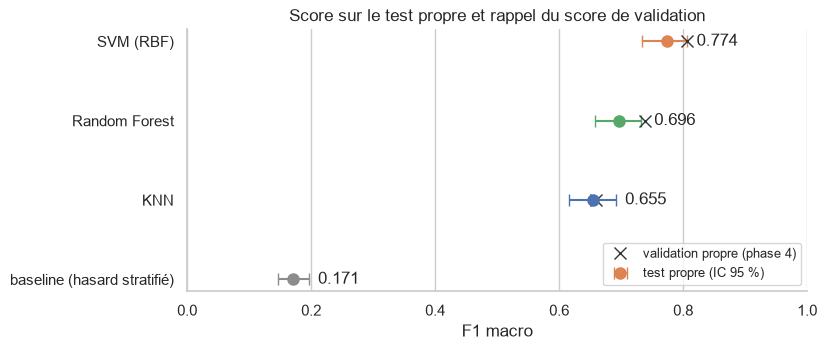

In [3]:
clean = metrics[metrics["subset"] == "test_clean"].set_index("model").loc[["svm", "rf", "knn", "baseline"]]
fig, ax = plt.subplots(figsize=(8, 3.4))
ypos = np.arange(len(clean))
for i, (m, r) in enumerate(clean.iterrows()):
    ax.errorbar(r["macro_f1"], i, xerr=[[r["macro_f1"] - r["macro_f1_ci_low"]], [r["macro_f1_ci_high"] - r["macro_f1"]]],
                fmt="o", color=MODEL_COLORS[m], capsize=4, ms=8, label="test propre (IC 95 %)" if i == 0 else None)
    if m in selection["models"]:
        ax.plot(selection["models"][m]["val_clean_macro_f1"], i, "x", color="#333333", ms=8,
                label="validation propre (phase 4)" if i == 0 else None)
    right = max(r["macro_f1_ci_high"], selection["models"].get(m, {}).get("val_clean_macro_f1", 0))
    ax.text(right + 0.015, i, f"{r['macro_f1']:.3f}", va="center")
ax.set_yticks(ypos, [MODEL_NAMES[m] for m in clean.index]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel("F1 macro"); ax.grid(axis="y", visible=False)
ax.set_title("Score sur le test propre et rappel du score de validation"); ax.legend(loc="lower right", fontsize=9)
plt.show()

- Le **SVM** reste le meilleur sur le test, devant le Random Forest et le KNN : l'ordre de la phase 4 est confirmé.
- Son score de test est un peu plus bas que celui de validation (choisir le meilleur réglage parmi 174 sur la validation
  donne toujours un léger optimisme), mais l'écart reste de l'ordre de la largeur de l'intervalle de confiance.
- Test officiel et test propre donnent presque le même score : les 10 images quasi dupliquées ne gonflaient pas le résultat.

## 2. Résultats par classe (test propre)

In [4]:
pc = pd.DataFrame(res["per_class"].values, index=pd.MultiIndex.from_tuples(res["per_class"].index), columns=CLASS_ORDER)
pc = pc.xs("test_clean", level=1).rename(index=MODEL_NAMES).T
pc["régions test propre"] = [int((y[masks["test_clean"]] == c).sum()) for c in CLASS_ORDER]
pc.round(3)

,baseline (hasard stratifié),SVM (RBF),Random Forest,KNN,régions test propre
dent,0.322,0.773,0.670,0.611,227
scratch,0.377,0.802,0.705,0.701,294
crack,0.125,0.557,0.517,0.467,70
glass shatter,0.123,0.823,0.766,0.671,71
lamp broken,0.079,0.791,0.684,0.621,68
tire flat,0.000,0.897,0.836,0.862,31


               precision    recall  f1-score   support

         dent      0.766     0.780     0.773       227
      scratch      0.761     0.847     0.802       294
        crack      0.711     0.457     0.557        70
glass shatter      0.829     0.817     0.823        71
  lamp broken      0.836     0.750     0.791        68
    tire flat      0.963     0.839     0.897        31

     accuracy                          0.779       761
    macro avg      0.811     0.748     0.774       761
 weighted avg      0.779     0.779     0.775       761



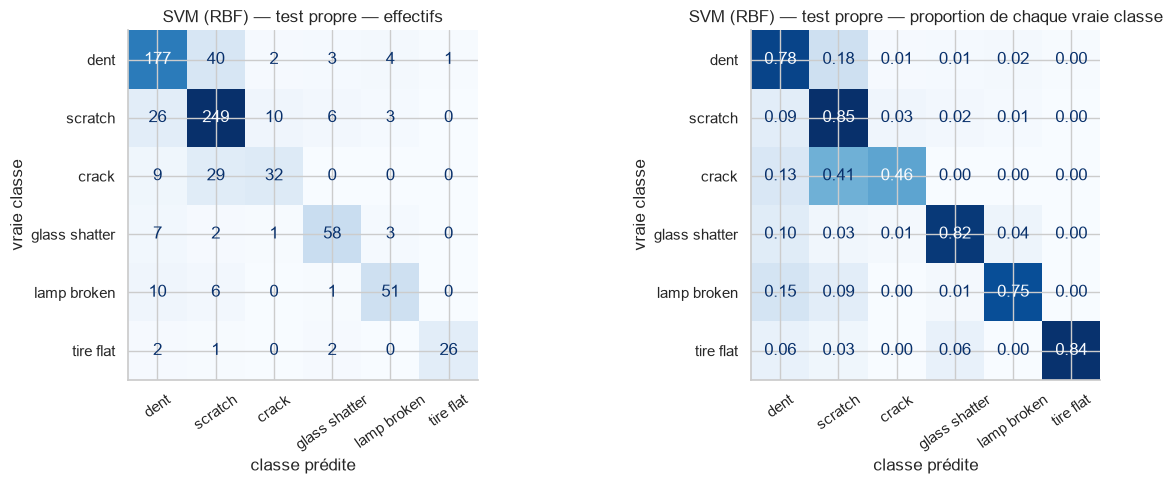

In [5]:
pred_sel = res["preds"][SEL][0]
m = masks["test_clean"]
print(classification_report(y[m], pred_sel[m], labels=CLASS_ORDER, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, norm, title in [(axes[0], None, "effectifs"), (axes[1], "true", "proportion de chaque vraie classe")]:
    ConfusionMatrixDisplay.from_predictions(y[m], pred_sel[m], labels=CLASS_ORDER, normalize=norm, cmap="Blues",
                                            values_format=".2f" if norm else "d", ax=ax, colorbar=False)
    ax.set_title(f"{MODEL_NAMES[SEL]} — test propre — {title}"); ax.set_xlabel("classe prédite"); ax.set_ylabel("vraie classe")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

- Comme sur la validation, **crack** est la classe la plus difficile : moins d'une fissure sur deux est reconnue, la plupart sont prises pour des rayures.
  Une fissure et une rayure sont toutes deux des traits fins ; HOG et la texture les distinguent mal sur un patch de 128 px.
- **dent ↔ scratch** est la confusion la plus fréquente en nombre (beaucoup de bosses portent aussi des rayures).
- **tire flat**, **glass shatter** et **lamp broken** ont une précision élevée : quand le modèle les annonce, il a presque toujours raison.

## 3. Peut-on faire confiance aux probabilités ?

L'application affiche la classe prédite **et sa probabilité**. Encore faut-il que « 90 % » veuille vraiment dire « juste 9 fois sur 10 ».

**Choix de la méthode (fait sur la validation, pas sur le test).** Un SVM ne fournit pas de probabilités ; on a comparé trois méthodes,
avec le meilleur réglage entraîné sur le train seul et mesuré sur la validation propre :

In [6]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import log_loss, f1_score
from src.models import train
from src.models.pipelines import build_preprocessor

X, meta = res["X"], res["meta"]
TR, VA = masks["train"], masks["val_clean"]
p = selection["models"]["svm"]["params"]
pre = Pipeline(build_preprocessor(p["pca"]))
Ztr, Zva = pre.fit_transform(X[TR]), pre.transform(X[VA])
svc = lambda **k: SVC(C=p["C"], gamma=p["gamma"], class_weight="balanced", random_state=0, **k)

def ece(proba, y_true, classes, bins=10):
    """Erreur de calibration : écart moyen entre confiance annoncée et taux de réussite réel."""
    conf, ok = proba.max(1), classes[proba.argmax(1)] == y_true
    edges = np.linspace(0, 1, bins + 1)
    return sum(((conf > a) & (conf <= b)).mean() * abs(ok[(conf > a) & (conf <= b)].mean() - conf[(conf > a) & (conf <= b)].mean())
               for a, b in zip(edges[:-1], edges[1:]) if ((conf > a) & (conf <= b)).any())

rows = []
for name, est in [("CalibratedClassifierCV sigmoïde", CalibratedClassifierCV(svc(), method="sigmoid", cv=5, ensemble=False)),
                  ("CalibratedClassifierCV température", CalibratedClassifierCV(svc(), method="temperature", cv=5, ensemble=False)),
                  ("libsvm (SVC probability=True) — retenue", svc(probability=True))]:
    proba = est.fit(Ztr, y[TR]).predict_proba(Zva)
    conf = proba.max(1)
    rows.append({"méthode": name, "F1 macro": f1_score(y[VA], est.classes_[proba.argmax(1)], average="macro"),
                 "log-loss ↓": log_loss(y[VA], proba, labels=est.classes_), "ECE ↓": ece(proba, y[VA], est.classes_),
                 "confiance 10e centile": np.percentile(conf, 10), "médiane": np.median(conf), "90e centile": np.percentile(conf, 90)})
pd.DataFrame(rows).round(3)

,méthode,F1 macro,log-loss ↓,ECE ↓,confiance 10e centile,médiane,90e centile
0,CalibratedClassifierCV sigmoïde,0.810,0.711,0.077,0.694,0.719,0.746
1,CalibratedClassifierCV température,0.805,0.691,0.055,0.726,0.736,0.752
2,libsvm (SVC probability=True) — retenue,0.806,0.576,0.029,0.497,0.810,0.981


Les trois méthodes donnent le même F1 (la classe prédite ne change pas), mais `CalibratedClassifierCV` produit des confiances presque
toutes égales à ≈ 0,7 : il calibre le score « une classe contre toutes » du SVM, qui n'est presque qu'un **nombre de votes** entre les
15 duels de classes. La méthode de libsvm calibre chaque duel puis les combine : elle est bien mieux calibrée (log-loss et ECE plus bas)
et ses confiances s'étalent réellement. C'est elle qu'utilise le modèle final
(`SVC(probability=True)`, déprécié depuis scikit-learn 1.9 mais disponible jusqu'en 1.11 ; la version du projet est figée à 1.9.1).

*Transparence* : le problème a été remarqué en regardant les confiances sur le test, mais la méthode a été choisie sur la validation
ci-dessus, et elle ne change aucune prédiction, donc aucun des scores des sections 1 et 2.

**Vérification sur le test** : diagramme de fiabilité (chaque point = un groupe de régions de confiance voisine).

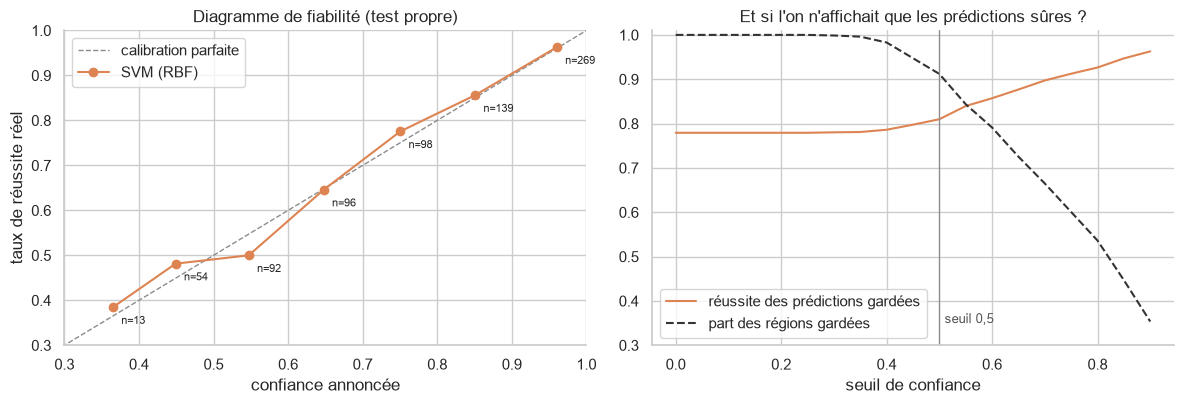

,confiance,réussite,régions
tranche,,,
"(0.0, 0.4]",0.365,0.385,13
"(0.4, 0.5]",0.449,0.481,54
"(0.5, 0.6]",0.547,0.500,92
"(0.6, 0.7]",0.648,0.646,96
"(0.7, 0.8]",0.750,0.776,98
"(0.8, 0.9]",0.851,0.856,139
"(0.9, 1.0]",0.960,0.963,269


In [7]:
d = detail[detail["test_clean"]].copy()
bins = [0, .4, .5, .6, .7, .8, .9, 1]
d["tranche"] = pd.cut(d["confidence"], bins)
rel = d.groupby("tranche", observed=True).agg(confiance=("confidence", "mean"), réussite=("correct", "mean"), régions=("correct", "size"))
cov = pd.DataFrame([{"seuil": t, "couverture": (d["confidence"] >= t).mean(), "réussite": d.loc[d["confidence"] >= t, "correct"].mean()}
                    for t in np.arange(0, 0.95, 0.05)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot([0, 1], [0, 1], "--", color="#8C8C8C", lw=1, label="calibration parfaite")
ax.plot(rel["confiance"], rel["réussite"], "o-", color=MODEL_COLORS[SEL], label=MODEL_NAMES[SEL])
for _, r in rel.iterrows():
    ax.annotate(f"n={int(r['régions'])}", (r["confiance"], r["réussite"]), textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.set_xlabel("confiance annoncée"); ax.set_ylabel("taux de réussite réel"); ax.set_xlim(0.3, 1); ax.set_ylim(0.3, 1)
ax.set_title("Diagramme de fiabilité (test propre)"); ax.legend(loc="upper left")
ax = axes[1]
ax.plot(cov["seuil"], cov["réussite"], "-", color=MODEL_COLORS[SEL], label="réussite des prédictions gardées")
ax.plot(cov["seuil"], cov["couverture"], "--", color="#333333", label="part des régions gardées")
ax.axvline(0.5, color="#8C8C8C", lw=1); ax.text(0.51, 0.35, "seuil 0,5", color="#555555", fontsize=9)
ax.set_xlabel("seuil de confiance"); ax.set_ylim(0.3, 1.01); ax.set_title("Et si l'on n'affichait que les prédictions sûres ?")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
rel.round(3)

In [8]:
t = 0.5
kept = d["confidence"] >= t
print(f"Seuil {t} (fixé a priori : moins d'une chance sur deux) : {kept.mean():.1%} des régions au-dessus, "
      f"réussite {d.loc[kept, 'correct'].mean():.1%} ; sous le seuil, réussite {d.loc[~kept, 'correct'].mean():.1%}")

Seuil 0.5 (fixé a priori : moins d'une chance sur deux) : 91.2% des régions au-dessus, réussite 81.0% ; sous le seuil, réussite 46.3%


Les confiances sont **fiables** : les points suivent la diagonale. Pour l'application, on affichera
« **résultat incertain** » quand la confiance est inférieure à **0,5** (seuil fixé a priori, pas optimisé sur le test),
en montrant alors les 2–3 classes les plus probables.

## 4. Analyse des erreurs : dans quelles situations le modèle se trompe-t-il ?

On croise les prédictions du test propre avec les informations conservées à part en phase 2
(`reports/cleaning/image_metadata.csv`, jamais utilisées pour l'entraînement) et la taille des régions.

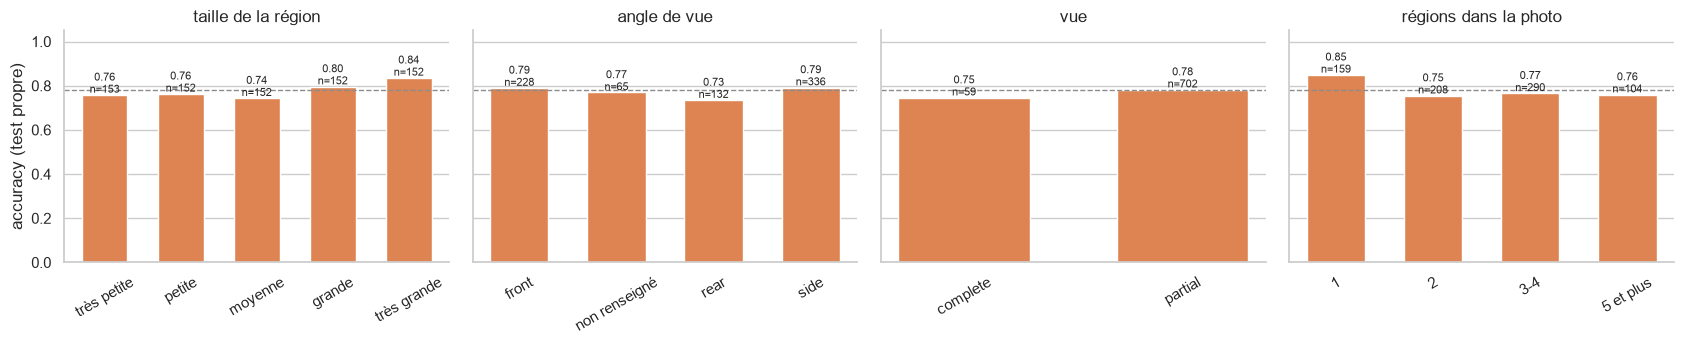

accuracy globale : 0.779 (ligne pointillée)


In [9]:
d["taille de la région"] = pd.qcut(d["bbox_rel_area"], 5, labels=["très petite", "petite", "moyenne", "grande", "très grande"])
d["angle de vue"] = d["shooting_angle"].fillna("non renseigné")
d["vue"] = d["complete_or_partial"].fillna("non renseigné")
d["régions dans la photo"] = pd.cut(d["regions_in_image"], [0, 1, 2, 4, 100], labels=["1", "2", "3-4", "5 et plus"])
factors = ["taille de la région", "angle de vue", "vue", "régions dans la photo"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
overall = d["correct"].mean()
for ax, f in zip(axes, factors):
    g = d.groupby(f, observed=True)["correct"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color=MODEL_COLORS[SEL], width=0.6)
    for i, (acc, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, acc + 0.01, f"{acc:.2f}\nn={n}", ha="center", fontsize=8)
    ax.axhline(overall, color="#8C8C8C", ls="--", lw=1)
    ax.set_title(f); ax.set_ylim(0, 1.05); ax.tick_params(axis="x", rotation=30); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("accuracy (test propre)")
plt.tight_layout(); plt.show()
print(f"accuracy globale : {overall:.3f} (ligne pointillée)")

In [10]:
print("Régions très petites (bbox_minuscule, < 16 px) :", int(d["tiny_bbox"].sum()), "dans le test propre,",
      int(d.loc[d["tiny_bbox"], "correct"].sum()), "bien classées")
d.groupby("true").agg(accuracy=("correct", "mean"), confiance_médiane=("confidence", "median"),
                      surface_relative_médiane=("bbox_rel_area", "median")).loc[CLASS_ORDER].round(3)

Régions très petites (bbox_minuscule, < 16 px) : 4 dans le test propre, 3 bien classées


,accuracy,confiance_médiane,surface_relative_médiane
true,,,
dent,0.780,0.811,0.085
scratch,0.847,0.815,0.067
crack,0.457,0.709,0.013
glass shatter,0.817,0.931,0.736
lamp broken,0.750,0.903,0.183
tire flat,0.839,0.999,0.347


### Exemples d'erreurs commises avec une forte confiance

Ce sont les cas les plus instructifs : le modèle s'est trompé **en étant sûr de lui**. Chaque vignette est le patch 128×128
réellement donné au modèle (même fonction `region_patch` que pour l'entraînement).

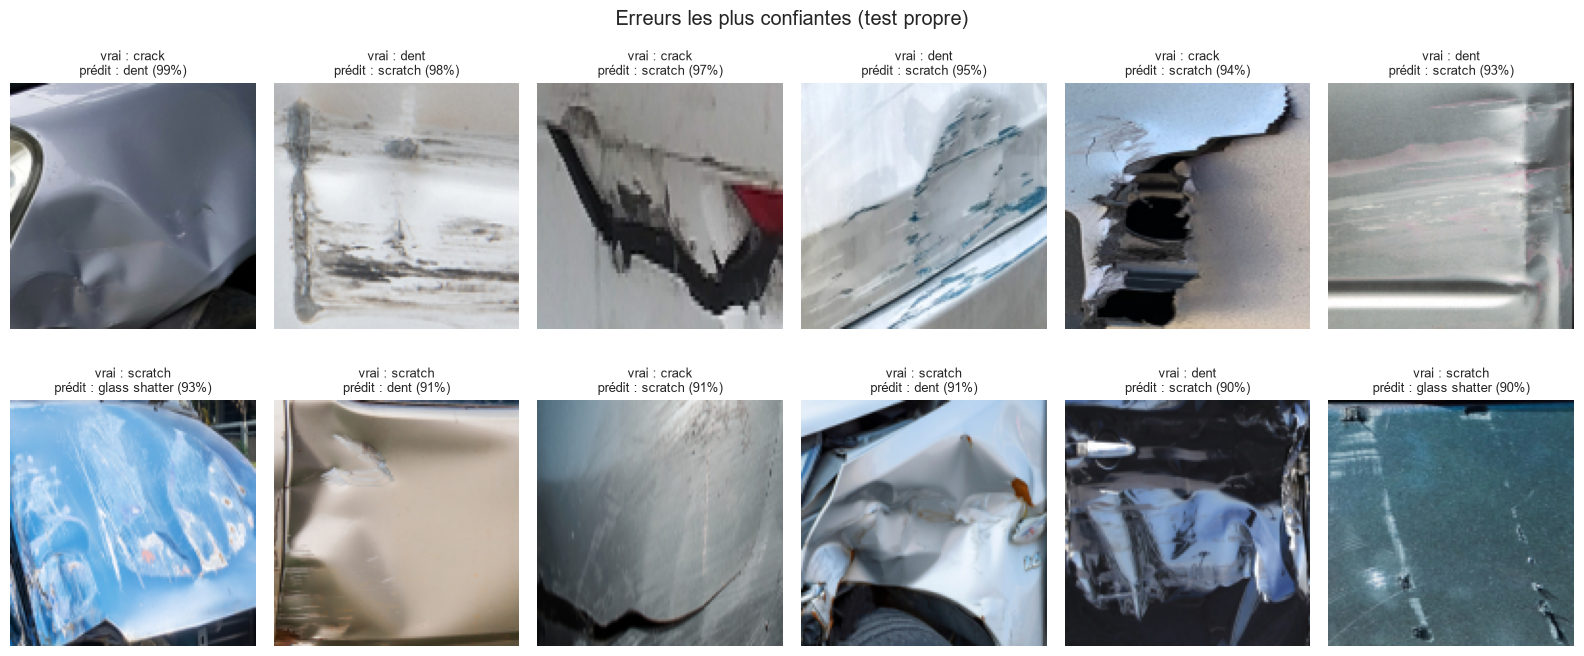

In [11]:
errors = d[~d["correct"]].sort_values("confidence", ascending=False).head(12)
regions_df = pd.read_csv(PROJECT_ROOT / "reports" / "cleaning" / "regions.csv")
fig, axes = plt.subplots(2, 6, figsize=(16, 7))
for ax, (_, r) in zip(axes.flat, errors.iterrows()):
    img = read_image_rgb(image_dir("test") / r["file_name"])
    b = regions_df[(regions_df["split"] == "test") & (regions_df["annotation_id"] == r["annotation_id"])].iloc[0]
    ax.imshow(region_patch(img, (b["bbox_x"], b["bbox_y"], b["bbox_w"], b["bbox_h"])))
    ax.set_title(f"vrai : {r['true']}\nprédit : {r['pred']} ({r['confidence']:.0%})", fontsize=9)
    ax.axis("off")
plt.suptitle("Erreurs les plus confiantes (test propre)"); plt.tight_layout(h_pad=2.5); plt.show()

## 5. Synthèse et limites
| Modèle | F1 macro test officiel | F1 macro test propre [IC 95 %] | accuracy test propre | rappel : F1 val propre |
|---|---|---|---|---|
| **SVM RBF (retenu)** | **0,776** | **0,774** [0,734 – 0,807] | 0,779 | 0,807 |
| Random Forest | 0,701 | 0,696 [0,657 – 0,732] | 0,689 | 0,738 |
| KNN | 0,659 | 0,655 [0,616 – 0,691] | 0,656 | 0,659 |
| baseline (hasard stratifié) | 0,170 | 0,171 | 0,271 | — |

**Ce qui fonctionne**
- Le SVM confirme sur des photos jamais vues son classement de la phase 4 : environ **78 % de régions bien classées**, F1 macro 0,77,
  4,5 fois la baseline ; l'écart avec la validation (0,81) est faible.
- *tire flat*, *glass shatter* et *lamp broken* sont bien reconnus (F1 ≥ 0,79, précision ≥ 0,83).
- Les **probabilités sont fiables** (diagramme de fiabilité proche de la diagonale) : au-dessus de 0,9 de confiance, 96 % de réussite ;
  sous 0,5, moins d'une chance sur deux. L'application signalera donc les résultats « incertains » sous 0,5.

**Limites**
- **crack** reste mal reconnu (rappel 0,46) : les fissures sont de petites zones fines, souvent prises pour des rayures.
- **dent ↔ scratch** : beaucoup d'erreurs, même confiantes, concernent des zones qui présentent les deux dommages à la fois
  (une bosse rayée) : une seule étiquette par zone ne décrit pas toujours la réalité.
- Le modèle se trompe un peu plus sur les petites régions et les vues arrière, et un peu moins sur les photos à un seul dommage,
  mais ces écarts (quelques points sur 60 à 330 régions) restent modestes.
- Les régions évaluées ici sont découpées avec les **bbox des annotateurs**. Dans l'application, c'est l'utilisateur qui recadre :
  un recadrage trop large ou mal centré dégradera le résultat (phase 3 : la marge fait baisser le score).
- Descripteurs « faits main » + modèle classique : le résultat est bien en dessous de ce qu'obtiendrait un réseau de neurones,
  exclu par le cahier des charges.
- **Une prédiction n'est pas une expertise d'assurance** : c'est une aide indicative, à confirmer par un professionnel.